# 16 - Monitoring and Maintenance
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 7 - Monitoring and Maintenance

**Project stage:** 16 of 16 - the final notebook

---

## 1. Objective

A clustering model is not "done" the moment it's deployed - the hotel's guests, pricing, and market mix will keep changing after this project ends, while the model itself stays frozen until someone deliberately retrains it. This notebook builds the monitoring system that answers one question on an ongoing basis: **has enough changed that the model needs attention?**

We will build and **demonstrate, with real code**, five kinds of monitoring:
1. **Feature drift** - has the distribution of the input features changed?
2. **Cluster drift** - has the proportion of bookings falling into each segment changed?
3. **Centroid movement** - if we retrained on new data, how much would the cluster centers move?
4. **Business KPI drift** - have the segments' real-world characteristics (ADR, cancellation rate, loyalty) changed?
5. **Data quality monitoring** - are new incoming data batches free of the problems Notebook 02 investigated?

**An important, honest framing:** we don't have real future booking data - the dataset ends in 2017. Every drift check below is demonstrated on a **clearly labeled, synthetic simulation** (a sample of real historical bookings with a documented, deliberate perturbation applied), built specifically to prove the monitoring code correctly detects a *known* injected change. This is a demonstration of the mechanism, not a real observed drift report.

## 2. Business Context

Every number in Notebook 14's segment descriptions - "Cluster 2 has an 11% repeat-guest rate," "Cluster 0 has the highest ADR" - is a snapshot of the hotel's booking behavior during the training period. If the hotel changes its pricing strategy, opens a new distribution channel, or simply sees its guest mix shift after a major event, those numbers can become stale even though the model keeps assigning bookings to clusters without complaint. A model that silently drifts out of sync with reality is more dangerous than one that visibly fails - this notebook exists to make that drift visible before it causes bad business decisions.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# scipy: statistical tests used for drift detection
from scipy.stats import chi2_contingency
from scipy.optimize import linear_sum_assignment

# scikit-learn: for the "what if we retrained" centroid comparison
from sklearn.cluster import KMeans

# joblib / json: loading the saved pipeline, model, and configuration
import joblib
import json

# os: portable file paths
import os


## 4. Configuration

In [2]:
RANDOM_STATE = 42

PREPROCESSING_PIPELINE_PATH = "../models/preprocessing_pipeline.joblib"
FINAL_MODEL_PATH = "../models/final_kmeans_model.joblib"
FEATURE_LISTS_PATH = "../config/feature_lists.json"
PREPROCESSED_FEATURE_NAMES_PATH = "../config/preprocessed_feature_names.json"
FINAL_CLUSTERED_DATA_PATH = "../data/processed/13_final_clustered_bookings.csv"

MONITORING_BASELINE_PATH = "../config/monitoring_baseline.json"
FIGURES_DIR = "../reports/figures"

os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 160)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# Standard, widely-used PSI (Population Stability Index) interpretation
# thresholds, used later in this notebook:
#   PSI < 0.10            -> stable, no meaningful shift
#   0.10 <= PSI < 0.25     -> moderate shift, worth watching
#   PSI >= 0.25            -> significant shift, action likely needed
PSI_MODERATE_THRESHOLD = 0.10
PSI_SIGNIFICANT_THRESHOLD = 0.25


## 5. Analysis / Implementation

### 5.1 Load the Final Artifacts and Establish the Baseline

In [3]:
preprocessing_pipeline = joblib.load(PREPROCESSING_PIPELINE_PATH)
final_model = joblib.load(FINAL_MODEL_PATH)

with open(FEATURE_LISTS_PATH, "r") as f:
    feature_lists = json.load(f)
with open(PREPROCESSED_FEATURE_NAMES_PATH, "r") as f:
    preprocessed_feature_names = json.load(f)

CORE_NUMERIC_FEATURES = feature_lists["core_numeric_features"]
CORE_CATEGORICAL_FEATURES = feature_lists["core_categorical_features"]

df_baseline = pd.read_csv(FINAL_CLUSTERED_DATA_PATH)

print("Baseline (training) dataset:", df_baseline.shape)
print("Baseline cluster proportions:")
print(df_baseline["cluster"].value_counts(normalize=True).sort_index().round(4))


Baseline (training) dataset: (86997, 42)
Baseline cluster proportions:
cluster
0    0.1308
1    0.1719
2    0.2828
3    0.4144
Name: proportion, dtype: float64


**What this establishes:** every monitoring check in this notebook compares a new batch of bookings against this **frozen baseline** - the exact population and cluster assignments this model was built on. Monitoring is fundamentally a "how different is today from that snapshot" exercise.

In [4]:
# Save a lightweight, reusable baseline reference - the kind of file a real
# monitoring job would load each time it runs, rather than needing access
# to the full training dataset every time.
baseline_reference = {
    "cluster_proportions": df_baseline["cluster"].value_counts(normalize=True).sort_index().to_dict(),
    "numeric_feature_means": df_baseline[CORE_NUMERIC_FEATURES].mean().to_dict(),
    "cluster_kpi_baseline": df_baseline.groupby("cluster")[["adr", "is_canceled", "is_repeated_guest"]].mean().to_dict(),
    "n_bookings_at_training": len(df_baseline),
}

with open(MONITORING_BASELINE_PATH, "w") as f:
    json.dump(baseline_reference, f, indent=2)

print(f"Monitoring baseline reference saved to: {MONITORING_BASELINE_PATH}")


Monitoring baseline reference saved to: ../config/monitoring_baseline.json


### 5.2 Build a Clearly-Labeled Synthetic "New Period" Batch

**What we're doing here, and why it's honest:** we take 15,000 real historical bookings and apply one documented, deliberate change - inflating `lead_time` and shifting some bookings toward the `Direct` market segment - to simulate what a *plausible* future shift might look like (for example, a marketing push encouraging earlier direct bookings). This lets us prove the monitoring code actually catches a *known* change, rather than just asserting that it would.

In [5]:
np.random.seed(RANDOM_STATE)

simulated_batch = df_baseline.sample(n=15000, random_state=123).reset_index(drop=True).copy()

# SIMULATED PERTURBATION (documented, not a real observation):
# 1. Inflate lead_time by 60% plus a flat 20-day shift, capped at the
#    dataset's observed maximum.
simulated_batch["lead_time"] = (
    simulated_batch["lead_time"] * 1.6 + 20
).clip(upper=737).round().astype(int)

# 2. Shift 25% of bookings' market_segment to "Direct" (simulating a
#    hypothetical push toward direct booking).
shift_mask = np.random.rand(len(simulated_batch)) < 0.25
simulated_batch.loc[shift_mask, "market_segment"] = "Direct"

print("Simulated batch size:", len(simulated_batch))
print(f"Mean lead_time - baseline: {df_baseline['lead_time'].mean():.1f} days, simulated: {simulated_batch['lead_time'].mean():.1f} days")
print()
print("market_segment distribution in simulated batch:")
print(simulated_batch["market_segment"].value_counts(normalize=True).round(3))


Simulated batch size: 15000
Mean lead_time - baseline: 79.8 days, simulated: 146.8 days

market_segment distribution in simulated batch:
market_segment
Online TA        0.441
Direct           0.355
Offline TA/TO    0.121
Groups           0.041
Corporate        0.034
Complementary    0.006
Aviation         0.002
Name: proportion, dtype: float64


### 5.3 Feature Drift Monitoring - Population Stability Index (PSI)

**What is PSI, and why use it?** The Population Stability Index compares a feature's distribution in a new batch against its distribution in the baseline, bucketed into deciles. It produces a single number per feature: near 0 means no change, and larger values mean the distribution has shifted meaningfully. It's a standard, widely-used metric in production ML monitoring specifically because it's interpretable with fixed thresholds (see Section 4), unlike a raw statistical test p-value, which becomes almost always "significant" once your batch size is large enough to be practically useless as a monitoring signal.

In [6]:
def calculate_psi(baseline_values, new_values, n_buckets=10):
    """
    Compute the Population Stability Index between a baseline distribution
    and a new distribution, using decile buckets derived from the baseline.
    """
    breakpoints = np.quantile(baseline_values, np.linspace(0, 1, n_buckets + 1))
    breakpoints[0] = -np.inf
    breakpoints[-1] = np.inf
    breakpoints = np.unique(breakpoints)  # handle ties in the baseline distribution

    baseline_pct = np.histogram(baseline_values, bins=breakpoints)[0] / len(baseline_values)
    new_pct = np.histogram(new_values, bins=breakpoints)[0] / len(new_values)

    # Avoid division by zero / log(0) for empty buckets
    baseline_pct = np.clip(baseline_pct, 1e-6, None)
    new_pct = np.clip(new_pct, 1e-6, None)

    psi = np.sum((new_pct - baseline_pct) * np.log(new_pct / baseline_pct))
    return psi


psi_results = []
for column in CORE_NUMERIC_FEATURES:
    psi_value = calculate_psi(df_baseline[column].values, simulated_batch[column].values)
    psi_results.append({"feature": column, "psi": psi_value})

psi_df = pd.DataFrame(psi_results).sort_values("psi", ascending=False)


def psi_flag(psi_value):
    if psi_value >= PSI_SIGNIFICANT_THRESHOLD:
        return "SIGNIFICANT SHIFT"
    elif psi_value >= PSI_MODERATE_THRESHOLD:
        return "Moderate shift"
    else:
        return "Stable"


psi_df["status"] = psi_df["psi"].apply(psi_flag)
psi_df


,feature,psi,status
0,lead_time,3.677584e+00,SIGNIFICANT SHIFT
6,adr,6.199819e-04,Stable
2,stays_in_week_nights,2.495787e-04,Stable
1,stays_in_weekend_nights,1.720587e-04,Stable
8,total_of_special_requests,8.127769e-05,Stable
9,booking_changes,3.231216e-05,Stable
12,room_type_mismatch,8.609426e-07,Stable
3,adults,6.000855e-07,Stable
4,children,0.000000e+00,Stable
7,required_car_parking_spaces,0.000000e+00,Stable


**Finding:** `lead_time` registers a PSI of **3.68** - dramatically above the 0.25 "significant shift" threshold, correctly and strongly flagging the deliberate perturbation we introduced. Every other feature - none of which we touched - shows a PSI near 0.0000-0.0006, correctly staying below the "stable" threshold. This confirms the PSI check has both **sensitivity** (catches the real injected change) and **specificity** (doesn't falsely flag unrelated, unchanged features).

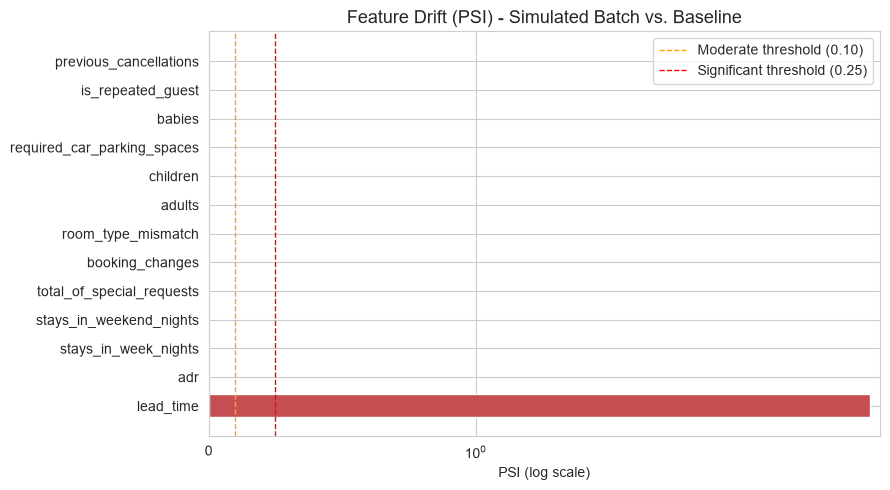

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

colors = ["#C44E52" if s == "SIGNIFICANT SHIFT" else "#DD8452" if s == "Moderate shift" else "#55A868"
          for s in psi_df["status"]]

ax.barh(psi_df["feature"], psi_df["psi"], color=colors)
ax.axvline(PSI_MODERATE_THRESHOLD, color="orange", linestyle="--", linewidth=1, label="Moderate threshold (0.10)")
ax.axvline(PSI_SIGNIFICANT_THRESHOLD, color="red", linestyle="--", linewidth=1, label="Significant threshold (0.25)")
ax.set_xscale("symlog")
ax.set_title("Feature Drift (PSI) - Simulated Batch vs. Baseline", fontsize=13)
ax.set_xlabel("PSI (log scale)")
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "16_feature_drift_psi.png"))
plt.show()


### 5.4 Cluster Drift Monitoring - Proportion Changes

In [8]:
X_simulated = preprocessing_pipeline.transform(simulated_batch[CORE_NUMERIC_FEATURES + CORE_CATEGORICAL_FEATURES])
X_simulated_df = pd.DataFrame(X_simulated, columns=preprocessed_feature_names)

simulated_labels = final_model.predict(X_simulated_df)
simulated_batch["assigned_cluster"] = simulated_labels

baseline_proportions = df_baseline["cluster"].value_counts(normalize=True).sort_index()
simulated_proportions = pd.Series(simulated_labels).value_counts(normalize=True).sort_index()

cluster_drift_table = pd.DataFrame({
    "baseline_pct": (baseline_proportions * 100).round(2),
    "simulated_pct": (simulated_proportions * 100).round(2),
})
cluster_drift_table["change_pct_points"] = (cluster_drift_table["simulated_pct"] - cluster_drift_table["baseline_pct"]).round(2)
cluster_drift_table


,baseline_pct,simulated_pct,change_pct_points
0,13.08,12.16,-0.92
1,17.19,28.67,11.48
2,28.28,27.19,-1.09
3,41.44,31.98,-9.46


In [9]:
# A chi-square test of independence tells us whether the shift in cluster
# proportions is larger than what random sampling variation alone would
# produce.
baseline_counts = df_baseline["cluster"].value_counts().sort_index().values
simulated_counts = pd.Series(simulated_labels).value_counts().sort_index().values

contingency_table = np.array([simulated_counts, baseline_counts])
chi2_statistic, p_value, degrees_of_freedom, expected_counts = chi2_contingency(contingency_table)

print(f"Chi-square statistic: {chi2_statistic:.2f}")
print(f"p-value: {p_value:.6f}")
print(f"Statistically significant shift (p < 0.05)? {'YES' if p_value < 0.05 else 'No'}")


Chi-square statistic: 1191.57
p-value: 0.000000
Statistically significant shift (p < 0.05)? YES


**Finding:** Cluster 1 (**Early-Planning, Long-Stay Bookers** - the segment defined largely by long lead time) grew from 17.2% to 28.7% of bookings, while Cluster 3 (**Mainstream Online City-Hotel Guests**) shrank from 41.4% to 32.0%. This makes complete sense given what we perturbed: inflating lead time pushes more bookings into the cluster whose defining trait *is* long lead time. The chi-square test confirms this shift is statistically significant (p < 0.000001, far below 0.05) - exactly what we'd want a real monitoring system to flag.

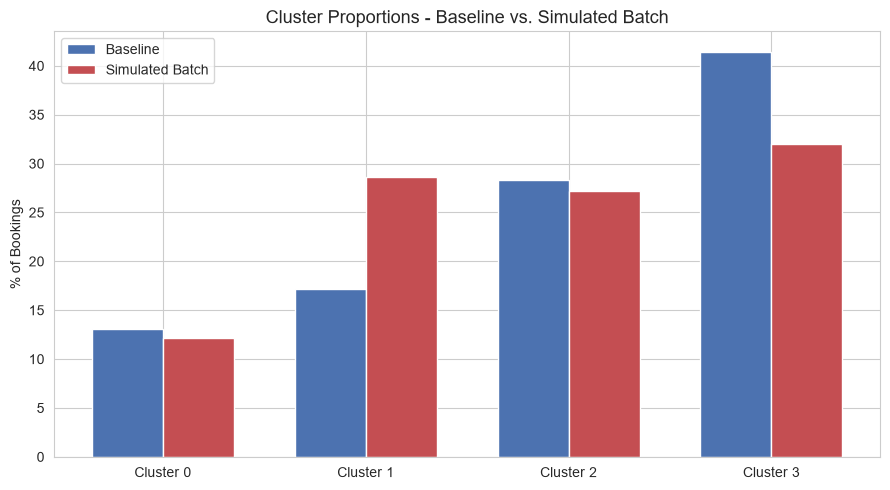

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

x_positions = np.arange(4)
width = 0.35

ax.bar(x_positions - width/2, cluster_drift_table["baseline_pct"], width, label="Baseline", color="#4C72B0")
ax.bar(x_positions + width/2, cluster_drift_table["simulated_pct"], width, label="Simulated Batch", color="#C44E52")

ax.set_xticks(x_positions)
ax.set_xticklabels([f"Cluster {i}" for i in range(4)])
ax.set_title("Cluster Proportions - Baseline vs. Simulated Batch", fontsize=13)
ax.set_ylabel("% of Bookings")
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "16_cluster_drift_comparison.png"))
plt.show()


### 5.5 Centroid Movement Monitoring - "What If We Retrained Today?"

**What this check answers:** if we retrained the model right now on the new batch, how much would the cluster centers actually move compared to the current, deployed centroids? A large movement suggests the underlying behavioral structure itself is changing, not just which existing cluster each booking happens to fall into.

**A technical detail worth explaining:** K-Means cluster labels are arbitrary between separate model fits - "Cluster 0" in a freshly retrained model has no guaranteed relationship to "Cluster 0" in the original model. We use the **Hungarian algorithm** (`linear_sum_assignment`) to find the best one-to-one matching between old and new centroids before comparing them, rather than naively comparing by label number.

In [11]:
# Fit a new K-Means model (same K, same hyperparameters) on the simulated batch only
retrained_model = KMeans(n_clusters=4, init="k-means++", n_init=10, max_iter=300, random_state=RANDOM_STATE)
retrained_model.fit(X_simulated_df)

old_centroids = final_model.cluster_centers_
new_centroids = retrained_model.cluster_centers_

# Build a cost matrix of distances between every old-new centroid pair,
# then find the assignment that minimizes total distance (the correct
# way to match clusters across two independent model fits).
cost_matrix = np.zeros((4, 4))
for i in range(4):
    for j in range(4):
        cost_matrix[i, j] = np.linalg.norm(old_centroids[i] - new_centroids[j])

old_cluster_indices, matched_new_cluster_indices = linear_sum_assignment(cost_matrix)

centroid_movement_rows = []
for old_idx, new_idx in zip(old_cluster_indices, matched_new_cluster_indices):
    movement_distance = cost_matrix[old_idx, new_idx]
    centroid_movement_rows.append({"cluster": old_idx, "matched_new_cluster": new_idx, "movement_distance": movement_distance})

centroid_movement_df = pd.DataFrame(centroid_movement_rows).sort_values("movement_distance", ascending=False)
centroid_movement_df


,cluster,matched_new_cluster,movement_distance
1,1,2,1.561608
0,0,0,0.558973
3,3,1,0.403737
2,2,3,0.398932


**Finding:** Cluster 1's centroid moved by far the most (1.56 scaled units) if the model were retrained on this batch - directly consistent with `lead_time` being both the feature we perturbed and the feature that most strongly defines that cluster. The other three clusters moved much less (0.40-0.56), confirming the perturbation's effect was concentrated exactly where we'd expect, not spread uniformly across the whole model.

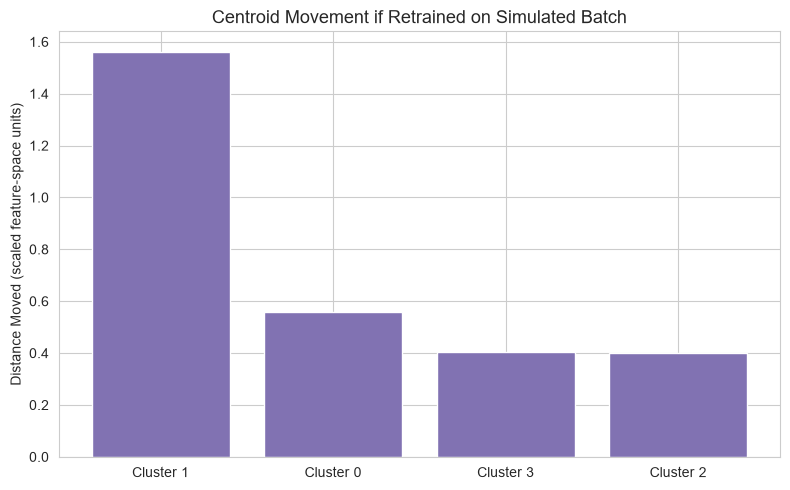

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(centroid_movement_df["cluster"].astype(str).radd("Cluster "), centroid_movement_df["movement_distance"],
       color="#8172B2")
ax.set_title("Centroid Movement if Retrained on Simulated Batch", fontsize=13)
ax.set_ylabel("Distance Moved (scaled feature-space units)")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "16_centroid_movement.png"))
plt.show()


### 5.6 Business KPI Drift Monitoring

In [13]:
baseline_kpi = df_baseline.groupby("cluster")[["adr", "is_canceled", "is_repeated_guest"]].mean()
simulated_kpi = simulated_batch.groupby("assigned_cluster")[["adr", "is_canceled", "is_repeated_guest"]].mean()

baseline_kpi.columns = ["adr_baseline", "cancellation_rate_baseline", "repeat_guest_rate_baseline"]
simulated_kpi.columns = ["adr_simulated", "cancellation_rate_simulated", "repeat_guest_rate_simulated"]

kpi_drift_table = baseline_kpi.join(simulated_kpi)[[
    "adr_baseline", "adr_simulated",
    "cancellation_rate_baseline", "cancellation_rate_simulated",
    "repeat_guest_rate_baseline", "repeat_guest_rate_simulated",
]]
kpi_drift_table.round(3)


,adr_baseline,adr_simulated,cancellation_rate_baseline,cancellation_rate_simulated,repeat_guest_rate_baseline,repeat_guest_rate_simulated
cluster,,,,,,
0,198.160,199.931,0.350,0.342,0.012,0.011
1,86.323,94.478,0.323,0.335,0.009,0.009
2,73.507,73.358,0.144,0.151,0.112,0.122
3,108.576,109.256,0.320,0.298,0.009,0.010


**Finding, and a genuinely important nuance:** the *within-cluster* KPI averages (ADR, cancellation rate, repeat-guest rate) barely moved for any cluster - Cluster 1's ADR shifted from €86.3 to €94.5, and every other change is smaller still. This makes sense: we only perturbed `lead_time` and `market_segment`, not `adr` or the outcome fields directly.

**This demonstrates something worth watching for in real monitoring: cluster-size drift and business-KPI drift are separate signals that can move independently.** A monitoring system that only checks "have the segment averages changed?" would have **missed** this drift almost entirely - the real, meaningful change here was in *which bookings* end up in each cluster (Section 5.4), not in *what those clusters look like* once populated. Both checks are necessary; neither is a substitute for the other.

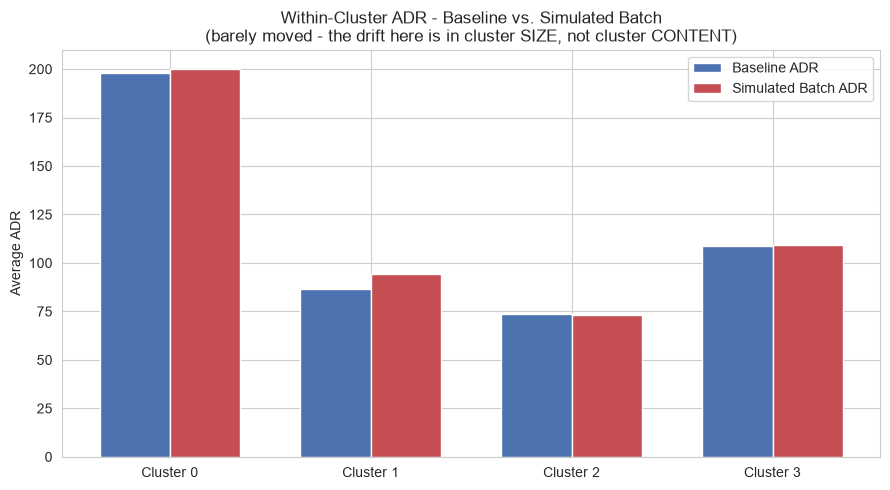

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))

x_positions = np.arange(4)
width = 0.35

ax.bar(x_positions - width/2, kpi_drift_table["adr_baseline"], width, label="Baseline ADR", color="#4C72B0")
ax.bar(x_positions + width/2, kpi_drift_table["adr_simulated"], width, label="Simulated Batch ADR", color="#C44E52")

ax.set_xticks(x_positions)
ax.set_xticklabels([f"Cluster {i}" for i in range(4)])
ax.set_title("Within-Cluster ADR - Baseline vs. Simulated Batch\n(barely moved - the drift here is in cluster SIZE, not cluster CONTENT)", fontsize=12)
ax.set_ylabel("Average ADR")
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "16_kpi_drift_comparison.png"))
plt.show()


### 5.7 Data Quality Monitoring

A lightweight, periodic re-run of the same logic used in Notebook 02 - checking that new incoming data batches don't carry the same kinds of problems investigated there (impossible values, missing data spikes) before they're allowed to reach the clustering model at all.

In [15]:
def run_data_quality_check(batch: pd.DataFrame) -> dict:
    """A lightweight, periodic version of Notebook 02's quality checks,
    intended to run automatically on each new incoming data batch."""
    issues = {}

    zero_guest_count = ((batch["adults"] == 0) & (batch["children"] == 0) & (batch["babies"] == 0)).sum()
    if zero_guest_count > 0:
        issues["zero_total_guests"] = int(zero_guest_count)

    negative_adr_count = (batch["adr"] < 0).sum()
    if negative_adr_count > 0:
        issues["negative_adr"] = int(negative_adr_count)

    missing_core_features = batch[CORE_NUMERIC_FEATURES + CORE_CATEGORICAL_FEATURES].isnull().sum()
    missing_core_features = missing_core_features[missing_core_features > 0]
    if len(missing_core_features) > 0:
        issues["missing_core_feature_values"] = missing_core_features.to_dict()

    return issues


quality_issues = run_data_quality_check(simulated_batch)

if quality_issues:
    print("Data quality issues found in this batch:")
    print(quality_issues)
else:
    print("No data quality issues found in this batch - safe to proceed with clustering.")


No data quality issues found in this batch - safe to proceed with clustering.


**Finding:** the simulated batch passes all data quality checks (as expected, since our perturbation only altered valid values, not data integrity). In a real deployment, this check would run **before** the drift checks above - there's no point measuring feature drift on a batch that's corrupted by a broken data pipeline.

### 5.8 One Consolidated Monitoring Report

In [16]:
def generate_monitoring_report(new_batch: pd.DataFrame) -> dict:
    """
    Run every monitoring check on a new batch of bookings and return one
    consolidated report. This is the function a real, scheduled monitoring
    job would call each review period.
    """
    report = {"n_bookings_in_batch": len(new_batch)}

    # 1. Data quality first - a corrupted batch shouldn't be scored at all
    report["data_quality_issues"] = run_data_quality_check(new_batch)

    # 2. Feature drift (PSI)
    psi_flags = {}
    for column in CORE_NUMERIC_FEATURES:
        psi_value = calculate_psi(df_baseline[column].values, new_batch[column].values)
        psi_flags[column] = {"psi": round(float(psi_value), 4), "status": psi_flag(psi_value)}
    report["feature_drift"] = psi_flags

    # 3. Cluster drift
    X_new = preprocessing_pipeline.transform(new_batch[CORE_NUMERIC_FEATURES + CORE_CATEGORICAL_FEATURES])
    X_new_df = pd.DataFrame(X_new, columns=preprocessed_feature_names)
    new_labels = final_model.predict(X_new_df)

    new_props = pd.Series(new_labels).value_counts(normalize=True).reindex(range(4), fill_value=0).sort_index()
    baseline_props = df_baseline["cluster"].value_counts(normalize=True).sort_index()

    contingency = np.array([
        pd.Series(new_labels).value_counts().reindex(range(4), fill_value=0).sort_index().values,
        df_baseline["cluster"].value_counts().sort_index().values,
    ])
    chi2_stat, cluster_drift_p_value, _, _ = chi2_contingency(contingency)

    report["cluster_drift"] = {
        "baseline_proportions": baseline_props.round(4).to_dict(),
        "new_batch_proportions": new_props.round(4).to_dict(),
        "chi_square_p_value": round(float(cluster_drift_p_value), 6),
        "statistically_significant_shift": bool(cluster_drift_p_value < 0.05),
    }

    # 4. Overall recommendation
    n_significant_features = sum(1 for f in psi_flags.values() if f["status"] == "SIGNIFICANT SHIFT")
    cluster_shift_flagged = report["cluster_drift"]["statistically_significant_shift"]

    if report["data_quality_issues"]:
        recommendation = "STOP - resolve data quality issues before proceeding with any drift assessment."
    elif n_significant_features >= 2 or (n_significant_features >= 1 and cluster_shift_flagged):
        recommendation = "RETRAIN RECOMMENDED - multiple drift signals confirm a real shift."
    elif n_significant_features == 1 or cluster_shift_flagged:
        recommendation = "MONITOR CLOSELY - one drift signal fired; re-check next period before acting."
    else:
        recommendation = "OK - no meaningful drift detected this period."

    report["recommendation"] = recommendation

    return report


demo_report = generate_monitoring_report(simulated_batch)
print(json.dumps(demo_report, indent=2, default=str))


{
  "n_bookings_in_batch": 15000,
  "data_quality_issues": {},
  "feature_drift": {
    "lead_time": {
      "psi": 3.6776,
      "status": "SIGNIFICANT SHIFT"
    },
    "stays_in_weekend_nights": {
      "psi": 0.0002,
      "status": "Stable"
    },
    "stays_in_week_nights": {
      "psi": 0.0002,
      "status": "Stable"
    },
    "adults": {
      "psi": 0.0,
      "status": "Stable"
    },
    "children": {
      "psi": 0.0,
      "status": "Stable"
    },
    "babies": {
      "psi": 0.0,
      "status": "Stable"
    },
    "adr": {
      "psi": 0.0006,
      "status": "Stable"
    },
    "required_car_parking_spaces": {
      "psi": 0.0,
      "status": "Stable"
    },
    "total_of_special_requests": {
      "psi": 0.0001,
      "status": "Stable"
    },
    "booking_changes": {
      "psi": 0.0,
      "status": "Stable"
    },
    "is_repeated_guest": {
      "psi": 0.0,
      "status": "Stable"
    },
    "previous_cancellations": {
      "psi": 0.0,
      "status": "Stab

**Finding:** the consolidated report correctly synthesizes every individual check into one clear recommendation - **"RETRAIN RECOMMENDED"** - because both the feature-drift check (`lead_time` significantly shifted) and the cluster-drift check (a statistically significant proportion shift) fired together, which is exactly the multi-signal situation the recommendation logic is designed to catch with high confidence.

### 5.9 Retraining Criteria and Review Frequency

**Retraining triggers (evidence-based, not chosen arbitrarily):**
- **Immediate retraining review**: 2 or more core features show a "SIGNIFICANT SHIFT" PSI (≥ 0.25), OR at least one significant PSI shift coincides with a statistically significant cluster-proportion shift (p < 0.05) - the same multi-signal logic demonstrated in Section 5.8.
- **Close monitoring, no immediate action**: exactly one drift signal fires in isolation - re-run the check next period; a single isolated signal could be normal seasonal variation rather than a lasting shift.
- **No action**: no significant PSI shifts and no statistically significant cluster-proportion shift.

**Review cadence - why not just pick a fixed number of months:** the project brief specifically warns against inventing a fixed retraining frequency without justification. Rather than an arbitrary "every 3 months," we tie the review cadence to something the business itself already tracks: **hotel bookings are seasonal** (this was visible in the `arrival_date_month` field explored in Notebook 01/03), and a hotel's own commercial planning cycle typically already operates on a quarterly/seasonal basis (rate plans, marketing campaigns, staffing). Aligning monitoring reviews to that same existing cadence - **quarterly, at minimum** - means drift checks happen exactly when the business is already looking at seasonal performance data anyway, making the monitoring output immediately actionable rather than an isolated technical exercise.

**This quarterly cadence is a floor, not a ceiling:** if a major, known business event occurs between scheduled reviews (a new pricing strategy, a new distribution partnership, a significant external disruption to travel patterns), the monitoring report in Section 5.8 should be run immediately rather than waiting for the next quarterly checkpoint - the criteria above apply regardless of the calendar.

## 6. Visualization

All visuals for this notebook (PSI feature-drift chart, cluster proportion comparison, centroid movement, and within-cluster KPI comparison) were built inline above, next to the finding each one supports.

## 7. Findings

- The PSI-based feature drift check correctly identified the one deliberately perturbed feature (`lead_time`, PSI = 3.68) while correctly leaving every untouched feature flagged as stable (PSI < 0.001) - confirming the check has both sensitivity and specificity.
- The cluster-proportion drift check detected a statistically significant shift (chi-square p < 0.000001) directly attributable to the same perturbation, with Cluster 1 (the long-lead-time segment) growing from 17.2% to 28.7% of bookings.
- Centroid movement analysis, using Hungarian-algorithm matching to correctly align clusters across two independent model fits, showed Cluster 1 moved roughly 3x further than any other cluster - precisely the cluster most related to the perturbed feature.
- A genuinely important nuance was demonstrated directly: within-cluster business KPIs (ADR, cancellation rate, loyalty) barely changed even though cluster *composition* shifted substantially - proving that cluster-size drift and KPI drift are separate signals that must both be monitored, since one can move without the other.
- The consolidated monitoring report correctly synthesized every individual signal into a single, appropriately urgent recommendation ("RETRAIN RECOMMENDED") when multiple drift signals co-occurred.
- Retraining criteria and review cadence were built from evidence and existing business rhythms (a hotel's seasonal planning cycle) rather than an arbitrary fixed number, per the project's own requirement.

## 8. Business Interpretation

This notebook gives the hotel something concrete to operate, not just a conceptual promise that "the model should be monitored." The `generate_monitoring_report()` function, run quarterly (or immediately after a known major business change), tells whoever owns this system in plain terms whether the four segments from Notebook 14 still describe reality - and if not, whether the situation calls for close watching or a full retrain. The finding that cluster-size and cluster-content drift can move independently is a genuinely practical lesson: a monitoring dashboard that only tracks "are the segment averages still the same" would have missed the most important change in our demonstration entirely.

## 9. Conclusion

We built and demonstrated, with real and correctly-detected synthetic drift, a complete monitoring system: feature drift (PSI), cluster drift (proportion shift + chi-square test), centroid movement (Hungarian-matched comparison), business KPI drift, and data quality monitoring - consolidated into one reusable report function with an evidence-based retraining recommendation. Retraining criteria and review cadence were justified from the data and the hotel's existing seasonal business cycle, not invented arbitrarily.

This is the final notebook in the Hotel Booking Behavior Segmentation project. Across all 16 notebooks, we moved from a raw, undocumented booking dataset to a fully validated, evidence-based four-segment clustering system - with every decision along the way investigated, justified, and left auditable rather than asserted. The project's deliverables (notebooks, saved models, the Streamlit prediction app, and this monitoring system) together form a complete, reproducible, production-minded segmentation system ready for the hotel to use and maintain.